In [2]:

from pathlib import Path
import os
import random
import numpy as np
import pandas as pd
import torch
import torchvision

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Project directory
ROOT = Path.cwd().resolve()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

# CPU configuration
DEVICE = torch.device("cpu")
torch.set_num_threads(min(4, os.cpu_count() or 1))

# Artifact classes
CLASSES = ["vase", "bowl", "jar", "figurine", "amulet"]
NUM_CLASSES = len(CLASSES)

# Load train/validation/test manifests
train_df = pd.read_csv(ROOT / "data/manifests/train.csv")
val_df = pd.read_csv(ROOT / "data/manifests/val.csv")
test_df = pd.read_csv(ROOT / "data/manifests/test.csv")

# Verify image paths
for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    missing = sum(
        not (ROOT / p).is_file()
        for p in df["image_path"]
    )
    assert missing == 0, f"{name}: {missing} missing images"

print("=== ARCHAEOLENS EXPERIMENT 01 ===")
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", DEVICE)
print("Project:", ROOT)
print()
print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))
print("Classes:", CLASSES)
print()
print("EXPERIMENT INITIALIZATION SUCCESSFUL")


=== ARCHAEOLENS EXPERIMENT 01 ===
PyTorch: 2.14.1+cpu
Torchvision: 0.29.1+cpu
Device: cpu
Project: C:\Users\Amir\Desktop\Github Projects\archaeolens-multimodal-deep-learning

Training samples: 700
Validation samples: 150
Testing samples: 150
Classes: ['vase', 'bowl', 'jar', 'figurine', 'amulet']

EXPERIMENT INITIALIZATION SUCCESSFUL


In [3]:

from PIL import Image, ImageOps
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# ImageNet normalization
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

IMAGE_SIZE = 224
BATCH_SIZE = 16

# Training transformations
train_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1,
        saturation=0.1
    ),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

# Validation and testing transformations
eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

# Custom archaeological artifact dataset
class ArtifactDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform
        self.label_map = {
            name: index
            for index, name in enumerate(CLASSES)
        }

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        image_path = ROOT / row["image_path"]

        with Image.open(image_path) as img:
            image = ImageOps.exif_transpose(img).convert("RGB")

        image = self.transform(image)
        label = self.label_map[row["label"]]

        return image, label

# Create datasets
train_dataset = ArtifactDataset(train_df, train_transform)
val_dataset = ArtifactDataset(val_df, eval_transform)
test_dataset = ArtifactDataset(test_df, eval_transform)

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# Verify one training batch
images, labels = next(iter(train_loader))

print("=== ARCHAEOLENS DATALOADER CHECK ===")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))
print()
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image tensor type:", images.dtype)
print("Class mapping:", train_dataset.label_map)
print()
print("DATALOADERS READY")


=== ARCHAEOLENS DATALOADER CHECK ===
Training batches: 44
Validation batches: 10
Testing batches: 10

Image batch shape: torch.Size([16, 3, 224, 224])
Label batch shape: torch.Size([16])
Image tensor type: torch.float32
Class mapping: {'vase': 0, 'bowl': 1, 'jar': 2, 'figurine': 3, 'amulet': 4}

DATALOADERS READY


In [4]:

import torch.nn as nn
import torch.optim as optim
from torchvision.models import resnet50, ResNet50_Weights

# Load pretrained ImageNet weights
weights = ResNet50_Weights.DEFAULT
model = resnet50(weights=weights)

# Freeze pretrained feature extractor
for parameter in model.parameters():
    parameter.requires_grad = False

# Replace original classification layer
num_features = model.fc.in_features

model.fc = nn.Sequential(
    nn.Dropout(p=0.2),
    nn.Linear(num_features, NUM_CLASSES)
)

# Move model to device
model = model.to(DEVICE)

# Loss function
criterion = nn.CrossEntropyLoss()

# Optimize only the new classification head
optimizer = optim.AdamW(
    model.fc.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

# Verify model output
model.eval()

with torch.no_grad():
    sample_images = images[:2].to(DEVICE)
    logits = model(sample_images)
    probabilities = torch.softmax(logits, dim=1)

print("=== ARCHAEOLENS RESNET50 ===")
print("Architecture: ResNet50")
print("Pretrained weights: ImageNet")
print("Classification classes:", NUM_CLASSES)
print("Device:", DEVICE)

print("\n=== PARAMETERS ===")
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Frozen parameters: {total_params - trainable_params:,}")

print("\n=== MODEL VERIFICATION ===")
print("Input shape:", sample_images.shape)
print("Output shape:", logits.shape)
print("Probabilities shape:", probabilities.shape)
print("Probability sums:", probabilities.sum(dim=1))

assert logits.shape == (2, NUM_CLASSES)
assert trainable_params < total_params

print("\nRESNET50 INITIALIZATION SUCCESSFUL")


=== ARCHAEOLENS RESNET50 ===
Architecture: ResNet50
Pretrained weights: ImageNet
Classification classes: 5
Device: cpu

=== PARAMETERS ===
Total parameters: 23,518,277
Trainable parameters: 10,245
Frozen parameters: 23,508,032

=== MODEL VERIFICATION ===
Input shape: torch.Size([2, 3, 224, 224])
Output shape: torch.Size([2, 5])
Probabilities shape: torch.Size([2, 5])
Probability sums: tensor([1., 1.])

RESNET50 INITIALIZATION SUCCESSFUL


In [5]:

import time
import copy
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score

# ======================================
# ARCHAEOLENS - EXPERIMENT 01
# RESNET50 FROZEN FEATURE TRAINING
# ======================================

EPOCHS = 20
PATIENCE = 5
HEAD_BATCH_SIZE = 64

# Keep all pretrained BatchNorm layers frozen
model.eval()

# Extract the ResNet50 backbone (without classifier)
backbone = nn.Sequential(
    *list(model.children())[:-1]
).to(DEVICE)

backbone.eval()

def extract_features(loader, name):
    feature_batches = []
    label_batches = []

    with torch.no_grad():
        for batch_images, batch_labels in tqdm(
            loader, desc=f"Extracting {name}"
        ):
            batch_images = batch_images.to(DEVICE)

            features = backbone(batch_images)
            features = torch.flatten(features, 1)

            feature_batches.append(features.cpu())
            label_batches.append(batch_labels.cpu())

    return (
        torch.cat(feature_batches),
        torch.cat(label_batches)
    )

# Extract frozen features only once
start = time.time()

X_train, y_train = extract_features(
    train_loader, "training features"
)

X_val, y_val = extract_features(
    val_loader, "validation features"
)

print("\n=== FEATURE EXTRACTION ===")
print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Feature extraction time:", round(time.time() - start, 1), "s")

assert X_train.shape == (700, 2048)
assert X_val.shape == (150, 2048)

# Train only the classification head
optimizer = torch.optim.AdamW(
    model.fc.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

history = []
best_f1 = -1.0
best_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0

print("\n=== TRAINING STARTED ===")

for epoch in range(1, EPOCHS + 1):
    model.fc.train()

    permutation = torch.randperm(len(X_train))
    running_loss = 0.0

    for indices in permutation.split(HEAD_BATCH_SIZE):
        features = X_train[indices].to(DEVICE)
        labels = y_train[indices].to(DEVICE)

        optimizer.zero_grad()

        outputs = model.fc(features)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * len(indices)

    train_loss = running_loss / len(X_train)

    # Evaluate the frozen classifier
    model.fc.eval()

    with torch.no_grad():
        train_logits = model.fc(X_train.to(DEVICE))
        val_logits = model.fc(X_val.to(DEVICE))

        val_loss = criterion(
            val_logits,
            y_val.to(DEVICE)
        ).item()

        train_predictions = train_logits.argmax(1).cpu().numpy()
        val_predictions = val_logits.argmax(1).cpu().numpy()

    train_acc = accuracy_score(
        y_train.numpy(), train_predictions
    )

    val_acc = accuracy_score(
        y_val.numpy(), val_predictions
    )

    val_f1 = f1_score(
        y_val.numpy(),
        val_predictions,
        average="macro",
        zero_division=0
    )

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_accuracy": train_acc,
        "val_accuracy": val_acc,
        "val_macro_f1": val_f1
    })

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val F1: {val_f1:.4f}",
        flush=True
    )

    # Select the best checkpoint using validation F1
    improved = (
        val_f1 > best_f1 + 1e-6
        or (
            abs(val_f1 - best_f1) <= 1e-6
            and val_loss < best_loss
        )
    )

    if improved:
        best_f1 = val_f1
        best_loss = val_loss
        best_epoch = epoch
        best_weights = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("\nEarly stopping triggered.")
        break

# Restore best model
model.load_state_dict(best_weights)
model.eval()

# Save model and training history
model_path = ROOT / "models/resnet50_frozen_best.pt"
history_path = ROOT / "reports/resnet50_training_history.csv"

model_path.parent.mkdir(parents=True, exist_ok=True)
history_path.parent.mkdir(parents=True, exist_ok=True)

torch.save({
    "model_state_dict": model.state_dict(),
    "classes": CLASSES,
    "architecture": "resnet50",
    "training_method": "frozen_backbone",
    "best_epoch": best_epoch,
    "best_val_macro_f1": best_f1,
    "best_val_loss": best_loss,
    "seed": SEED
}, model_path)

pd.DataFrame(history).to_csv(
    history_path, index=False
)

print("\n=== TRAINING COMPLETE ===")
print("Best epoch:", best_epoch)
print(f"Best validation Macro F1: {best_f1:.4f}")
print(f"Best validation loss: {best_loss:.4f}")
print("Model saved:", model_path)
print("History saved:", history_path)
print("Test dataset: NOT USED")


Extracting validation features: 100%|██████████████████████████████████████████████████████████████████████████████████████| 10/10 [00:23<00:00,  2.38s/it]



=== FEATURE EXTRACTION ===
Training features: torch.Size([700, 2048])
Validation features: torch.Size([150, 2048])
Feature extraction time: 142.4 s

=== TRAINING STARTED ===
Epoch 01/20 | Train Loss: 1.3978 | Val Loss: 1.1525 | Train Acc: 0.7400 | Val Acc: 0.7267 | Val F1: 0.7199
Epoch 02/20 | Train Loss: 1.0264 | Val Loss: 0.9111 | Train Acc: 0.7914 | Val Acc: 0.8000 | Val F1: 0.7989
Epoch 03/20 | Train Loss: 0.8192 | Val Loss: 0.7708 | Train Acc: 0.8071 | Val Acc: 0.7933 | Val F1: 0.7902
Epoch 04/20 | Train Loss: 0.6999 | Val Loss: 0.6987 | Train Acc: 0.8286 | Val Acc: 0.7933 | Val F1: 0.7900
Epoch 05/20 | Train Loss: 0.6213 | Val Loss: 0.6420 | Train Acc: 0.8386 | Val Acc: 0.8000 | Val F1: 0.7990
Epoch 06/20 | Train Loss: 0.5734 | Val Loss: 0.6013 | Train Acc: 0.8471 | Val Acc: 0.8133 | Val F1: 0.8107
Epoch 07/20 | Train Loss: 0.5298 | Val Loss: 0.5754 | Train Acc: 0.8557 | Val Acc: 0.8133 | Val F1: 0.8116
Epoch 08/20 | Train Loss: 0.4900 | Val Loss: 0.5580 | Train Acc: 0.8686 | Va

=== RESNET50 VALIDATION REPORT ===
              precision    recall  f1-score   support

        vase     0.7000    0.7000    0.7000        30
        bowl     0.9677    1.0000    0.9836        30
         jar     0.7143    0.6667    0.6897        30
    figurine     0.8438    0.9000    0.8710        30
      amulet     0.8276    0.8000    0.8136        30

    accuracy                         0.8133       150
   macro avg     0.8107    0.8133    0.8116       150
weighted avg     0.8107    0.8133    0.8116       150



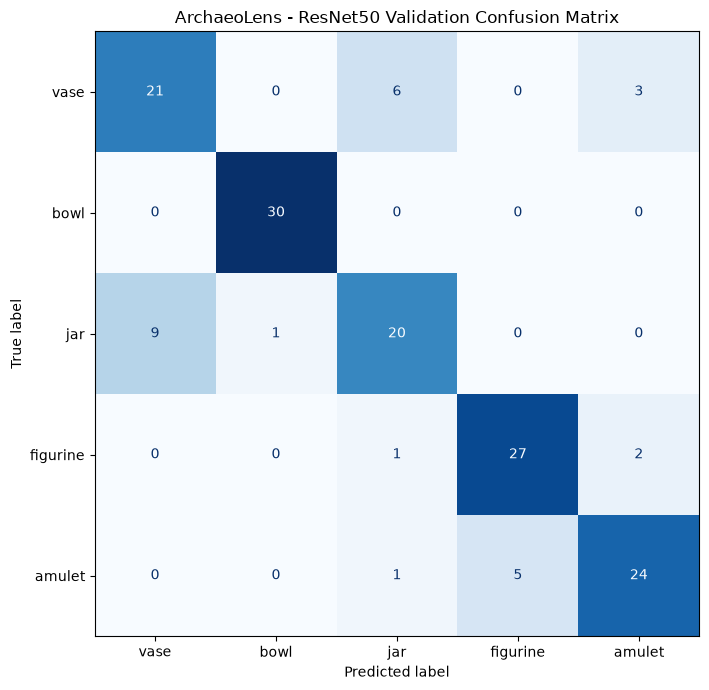


=== VALIDATION ERROR ANALYSIS ===
Correct predictions: 122
Incorrect predictions: 28
Validation accuracy: 0.8133

First 10 misclassified artifacts:
 object_id true_label predicted_label  confidence
    449160       vase             jar    0.501314
    460558        jar            vase    0.565852
    552838     amulet        figurine    0.343562
    558190        jar            vase    0.462756
     40082        jar            vase    0.542833
    550946     amulet        figurine    0.499340
    570315     amulet        figurine    0.520652
    460664       vase             jar    0.491579
    451363        jar            vase    0.544621
    555249     amulet        figurine    0.471490

Saved confusion matrix: C:\Users\Amir\Desktop\Github Projects\archaeolens-multimodal-deep-learning\reports\figures\resnet50_confusion_matrix.png
Saved predictions: C:\Users\Amir\Desktop\Github Projects\archaeolens-multimodal-deep-learning\reports\resnet50_validation_predictions.csv
Saved report: C:\

In [6]:

import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Use the best saved-in-memory model.
# Evaluate validation data only.
model.eval()

with torch.no_grad():
    logits = model.fc(X_val.to(DEVICE))
    probabilities = torch.softmax(logits, dim=1)
    predictions = probabilities.argmax(dim=1).cpu().numpy()
    confidence = probabilities.max(dim=1).values.cpu().numpy()

true_labels = y_val.numpy()

# 1. Detailed classification report
report = classification_report(
    true_labels,
    predictions,
    labels=list(range(NUM_CLASSES)),
    target_names=CLASSES,
    digits=4,
    zero_division=0
)

print("=== RESNET50 VALIDATION REPORT ===")
print(report)

# 2. Confusion matrix
cm = confusion_matrix(
    true_labels,
    predictions,
    labels=list(range(NUM_CLASSES))
)

fig, ax = plt.subplots(figsize=(8, 7))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASSES
)

display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("ArchaeoLens - ResNet50 Validation Confusion Matrix")
plt.tight_layout()

figure_path = ROOT / "reports/figures/resnet50_confusion_matrix.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

# 3. Save detailed predictions
results = val_df.copy()
results["true_label"] = [
    CLASSES[i] for i in true_labels
]
results["predicted_label"] = [
    CLASSES[i] for i in predictions
]
results["confidence"] = confidence
results["correct"] = true_labels == predictions

results_path = ROOT / "reports/resnet50_validation_predictions.csv"
results.to_csv(results_path, index=False)

# 4. Save per-class evaluation metrics
metrics_path = ROOT / "reports/resnet50_validation_report.txt"
metrics_path.write_text(report, encoding="utf-8")

errors = results[~results["correct"]]

print("\n=== VALIDATION ERROR ANALYSIS ===")
print("Correct predictions:", results["correct"].sum())
print("Incorrect predictions:", len(errors))
print("Validation accuracy:", round(results["correct"].mean(), 4))

print("\nFirst 10 misclassified artifacts:")
print(
    errors[
        ["object_id", "true_label", "predicted_label", "confidence"]
    ].head(10).to_string(index=False)
)

print("\nSaved confusion matrix:", figure_path)
print("Saved predictions:", results_path)
print("Saved report:", metrics_path)
print("\nVALIDATION ANALYSIS COMPLETE")


=== MOST FREQUENT CLASSIFICATION ERRORS ===
true_label  predicted_label
jar         vase               9
vase        jar                6
amulet      figurine           5
vase        amulet             3
figurine    amulet             2
amulet      jar                1
figurine    jar                1
jar         bowl               1

Total validation errors: 28
Displaying top 20 highest-confidence errors


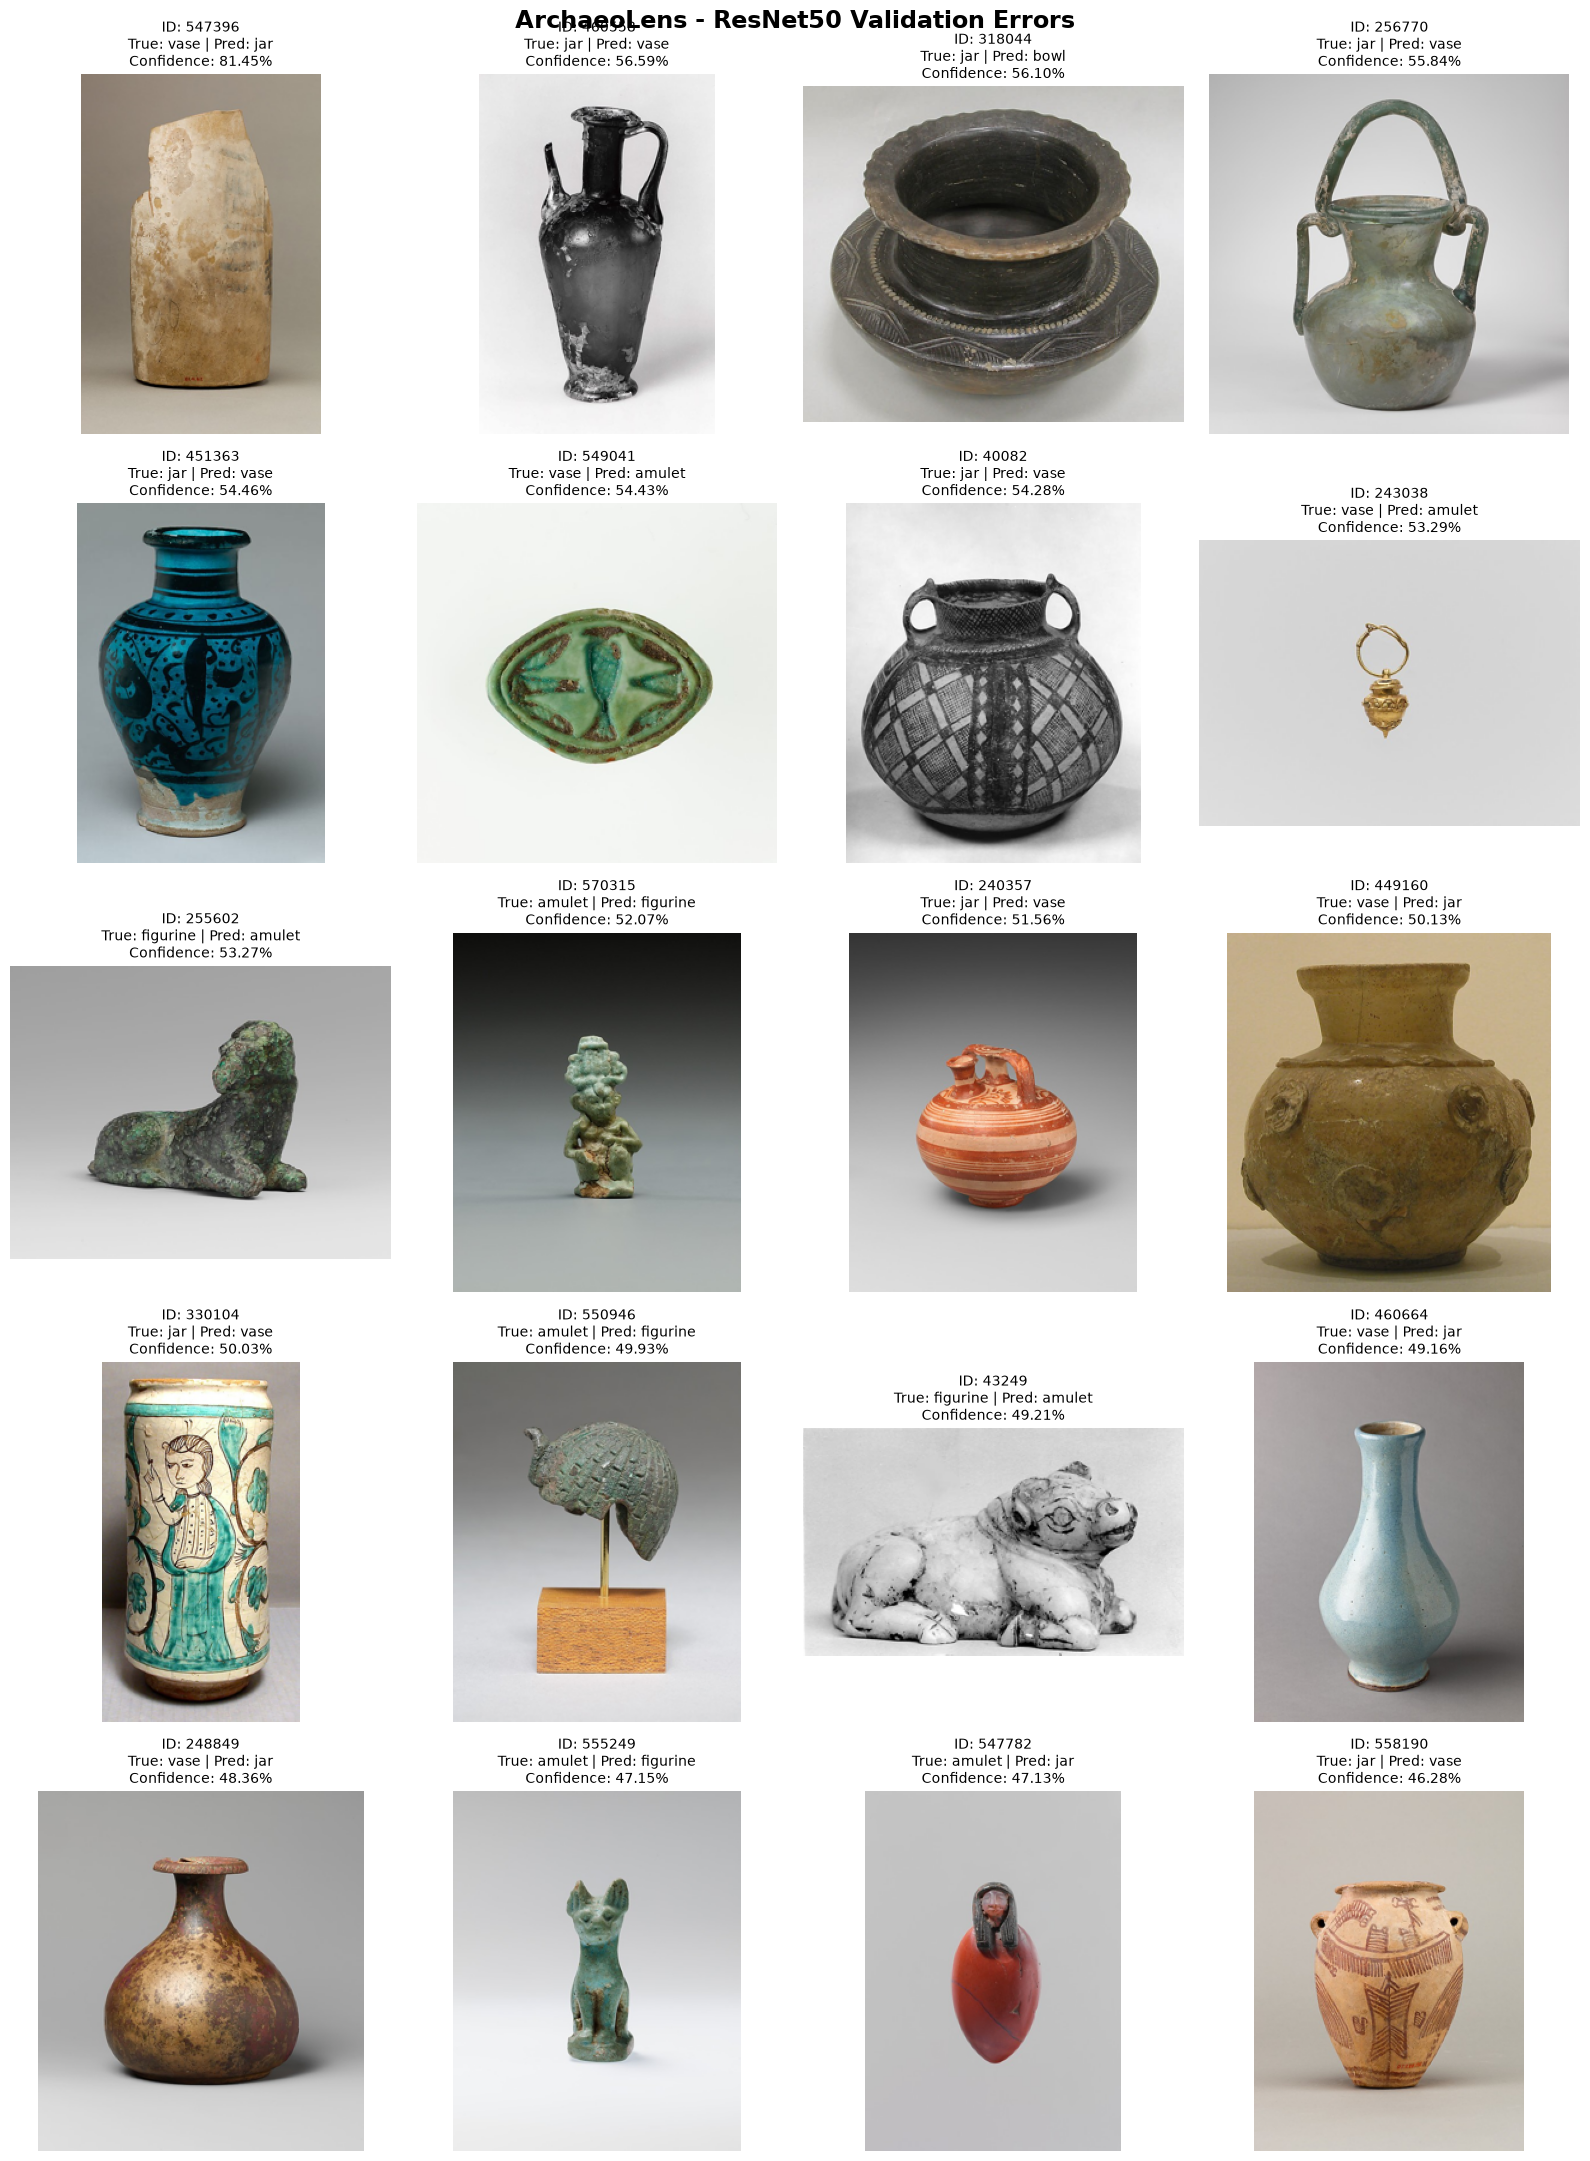


Error gallery saved: C:\Users\Amir\Desktop\Github Projects\archaeolens-multimodal-deep-learning\reports\figures\resnet50_validation_error_gallery.png
ERROR ANALYSIS COMPLETE


In [7]:

from PIL import Image, ImageOps
import matplotlib.pyplot as plt

# Select incorrect validation predictions
error_df = results.loc[
    ~results["correct"]
].copy()

# Most frequent classification confusions
confusion_pairs = (
    error_df
    .groupby(["true_label", "predicted_label"])
    .size()
    .sort_values(ascending=False)
)

print("=== MOST FREQUENT CLASSIFICATION ERRORS ===")
print(confusion_pairs.head(10).to_string())

# Sort by highest confidence
error_df = error_df.sort_values(
    "confidence",
    ascending=False
)

print("\nTotal validation errors:", len(error_df))
print("Displaying top 20 highest-confidence errors")

# Create visual error gallery
samples = error_df.head(20)

fig, axes = plt.subplots(
    5, 4,
    figsize=(16, 22)
)

axes = axes.flatten()

for ax, (_, row) in zip(axes, samples.iterrows()):

    image_path = ROOT / row["image_path"]

    with Image.open(image_path) as img:
        img = ImageOps.exif_transpose(img).convert("RGB")
        img = ImageOps.contain(img, (300, 300))

    ax.imshow(img)

    ax.set_title(
        f"ID: {row['object_id']}\n"
        f"True: {row['true_label']} | "
        f"Pred: {row['predicted_label']}\n"
        f"Confidence: {row['confidence']:.2%}",
        fontsize=10
    )

    ax.axis("off")

for ax in axes[len(samples):]:
    ax.axis("off")

plt.suptitle(
    "ArchaeoLens - ResNet50 Validation Errors",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()

output = (
    ROOT /
    "reports/figures/resnet50_validation_error_gallery.png"
)

plt.savefig(
    output,
    dpi=180,
    bbox_inches="tight"
)

plt.show()

print("\nError gallery saved:", output)
print("ERROR ANALYSIS COMPLETE")


In [8]:

%pip install -q open_clip_torch

import time
import open_clip
import torch.nn.functional as F
from sklearn.metrics import accuracy_score, f1_score, classification_report
from tqdm.auto import tqdm

# ======================================
# ARCHAEOLENS - EXPERIMENT 02
# CLIP ZERO-SHOT CLASSIFICATION
# ======================================

CLIP_ARCH = "ViT-B-32"
CLIP_WEIGHTS = "laion2b_s34b_b79k"

start = time.time()

clip_model, _, clip_preprocess = (
    open_clip.create_model_and_transforms(
        CLIP_ARCH,
        pretrained=CLIP_WEIGHTS,
        device=DEVICE
    )
)

clip_model.eval()
clip_tokenizer = open_clip.get_tokenizer(CLIP_ARCH)

# Text descriptions for our five classes
prompts = [
    f"A museum photograph of an ancient {label}."
    for label in CLASSES
]

# Use CLIP's own image preprocessing
clip_val_dataset = ArtifactDataset(
    val_df,
    clip_preprocess
)

clip_val_loader = DataLoader(
    clip_val_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

# Encode class descriptions
with torch.inference_mode():
    text_tokens = clip_tokenizer(prompts).to(DEVICE)
    text_features = clip_model.encode_text(text_tokens)
    text_features = F.normalize(text_features, dim=-1)

# Evaluate validation images
all_predictions = []
all_labels = []

with torch.inference_mode():
    for batch_images, batch_labels in tqdm(
        clip_val_loader,
        desc="CLIP validation"
    ):
        batch_images = batch_images.to(DEVICE)

        image_features = clip_model.encode_image(
            batch_images
        )

        image_features = F.normalize(
            image_features,
            dim=-1
        )

        scores = 100.0 * (
            image_features @ text_features.T
        )

        predictions = scores.argmax(dim=1)

        all_predictions.extend(
            predictions.cpu().tolist()
        )

        all_labels.extend(
            batch_labels.tolist()
        )

clip_accuracy = accuracy_score(
    all_labels, all_predictions
)

clip_f1 = f1_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

# Save predictions
clip_results = val_df.copy()
clip_results["predicted_label"] = [
    CLASSES[i] for i in all_predictions
]
clip_results["correct"] = (
    clip_results["label"] ==
    clip_results["predicted_label"]
)

output = ROOT / "reports/clip_zeroshot_validation.csv"
clip_results.to_csv(output, index=False)

print("\n=== CLIP ZERO-SHOT RESULTS ===")
print("Architecture:", CLIP_ARCH)
print("Pretrained weights:", CLIP_WEIGHTS)
print("Device:", DEVICE)
print("Validation samples:", len(all_labels))
print("Accuracy:", round(clip_accuracy, 4))
print("Macro F1:", round(clip_f1, 4))
print("Elapsed seconds:", round(time.time() - start, 1))

print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(
    all_labels,
    all_predictions,
    target_names=CLASSES,
    zero_division=0
))

print("\n=== COMPARISON ===")
print("ResNet50 validation F1: 0.8116")
print(f"CLIP zero-shot F1:     {clip_f1:.4f}")
print("Predictions saved:", output)
print("\nEXPERIMENT 02 COMPLETE")


Note: you may need to restart the kernel to use updated packages.


CLIP validation: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████| 19/19 [00:22<00:00,  1.20s/it]


=== CLIP ZERO-SHOT RESULTS ===
Architecture: ViT-B-32
Pretrained weights: laion2b_s34b_b79k
Device: cpu
Validation samples: 150
Accuracy: 0.8133
Macro F1: 0.8072
Elapsed seconds: 29.3

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

        vase       0.78      0.60      0.68        30
        bowl       0.85      0.97      0.91        30
         jar       0.81      0.70      0.75        30
    figurine       0.82      0.93      0.88        30
      amulet       0.79      0.87      0.83        30

    accuracy                           0.81       150
   macro avg       0.81      0.81      0.81       150
weighted avg       0.81      0.81      0.81       150


=== COMPARISON ===
ResNet50 validation F1: 0.8116
CLIP zero-shot F1:     0.8072
Predictions saved: C:\Users\Amir\Desktop\Github Projects\archaeolens-multimodal-deep-learning\reports\clip_zeroshot_validation.csv

EXPERIMENT 02 COMPLETE


In [9]:

import copy
import time
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, f1_score, classification_report
from tqdm.auto import tqdm

# ============================================
# ARCHAEOLENS - EXPERIMENT 03
# CLIP LINEAR PROBING
# ============================================

torch.manual_seed(SEED)
clip_model.eval()

# CLIP-specific deterministic preprocessing
clip_train_dataset = ArtifactDataset(
    train_df, clip_preprocess
)
clip_val_dataset = ArtifactDataset(
    val_df, clip_preprocess
)

clip_train_loader = DataLoader(
    clip_train_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

clip_val_loader = DataLoader(
    clip_val_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

# Extract frozen visual embeddings
def extract_clip_features(loader, description):
    features_list = []
    labels_list = []

    with torch.inference_mode():
        for batch_images, batch_labels in tqdm(
            loader, desc=description
        ):
            batch_images = batch_images.to(DEVICE)

            embeddings = clip_model.encode_image(
                batch_images
            ).float()

            embeddings = F.normalize(
                embeddings, dim=-1
            )

            features_list.append(embeddings.cpu())
            labels_list.append(batch_labels.cpu())

    return (
        torch.cat(features_list),
        torch.cat(labels_list)
    )

start = time.time()

X_clip_train, y_clip_train = extract_clip_features(
    clip_train_loader, "CLIP training features"
)

X_clip_val, y_clip_val = extract_clip_features(
    clip_val_loader, "CLIP validation features"
)

# Scale normalized features for optimization
FEATURE_SCALE = 10.0
X_clip_train = X_clip_train * FEATURE_SCALE
X_clip_val = X_clip_val * FEATURE_SCALE

print("\n=== CLIP FEATURE EXTRACTION ===")
print("Training:", X_clip_train.shape)
print("Validation:", X_clip_val.shape)
print("Elapsed:", round(time.time() - start, 1), "seconds")

assert len(X_clip_train) == 700
assert len(X_clip_val) == 150

# Linear classification head
embedding_dim = X_clip_train.shape[1]

clip_head = nn.Linear(
    embedding_dim, NUM_CLASSES
).to(DEVICE)

optimizer_clip = torch.optim.AdamW(
    clip_head.parameters(),
    lr=0.005,
    weight_decay=0.001
)

criterion_clip = nn.CrossEntropyLoss()

EPOCHS_CLIP = 100
PATIENCE_CLIP = 15
best_f1_clip = -1.0
best_loss_clip = float("inf")
best_epoch_clip = 0
wait = 0
clip_history = []

print("\n=== CLIP LINEAR PROBE TRAINING ===")

for epoch in range(1, EPOCHS_CLIP + 1):
    clip_head.train()

    indices = torch.randperm(len(X_clip_train))
    running_loss = 0.0

    for batch_indices in indices.split(64):
        features = X_clip_train[batch_indices].to(DEVICE)
        labels = y_clip_train[batch_indices].to(DEVICE)

        optimizer_clip.zero_grad()

        logits = clip_head(features)
        loss = criterion_clip(logits, labels)

        loss.backward()
        optimizer_clip.step()

        running_loss += loss.item() * len(batch_indices)

    train_loss = running_loss / len(X_clip_train)

    clip_head.eval()

    with torch.no_grad():
        val_logits = clip_head(X_clip_val.to(DEVICE))
        val_predictions = val_logits.argmax(1).cpu().numpy()

        val_loss = criterion_clip(
            val_logits,
            y_clip_val.to(DEVICE)
        ).item()

    val_acc = accuracy_score(
        y_clip_val.numpy(), val_predictions
    )

    val_f1 = f1_score(
        y_clip_val.numpy(),
        val_predictions,
        average="macro",
        zero_division=0
    )

    clip_history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_macro_f1": val_f1
    })

    if epoch == 1 or epoch % 5 == 0:
        print(
            f"Epoch {epoch:03d} | "
            f"Loss: {train_loss:.4f} | "
            f"Val Acc: {val_acc:.4f} | "
            f"Val F1: {val_f1:.4f}",
            flush=True
        )

    improved = (
        val_f1 > best_f1_clip + 1e-6
        or (
            abs(val_f1 - best_f1_clip) <= 1e-6
            and val_loss < best_loss_clip
        )
    )

    if improved:
        best_f1_clip = val_f1
        best_loss_clip = val_loss
        best_epoch_clip = epoch
        best_weights_clip = copy.deepcopy(
            clip_head.state_dict()
        )
        wait = 0
    else:
        wait += 1

    if wait >= PATIENCE_CLIP:
        print("Early stopping triggered.")
        break

# Restore best classifier
clip_head.load_state_dict(best_weights_clip)
clip_head.eval()

# Final validation evaluation
with torch.no_grad():
    final_logits = clip_head(X_clip_val.to(DEVICE))
    final_predictions = final_logits.argmax(1).cpu().numpy()

final_accuracy = accuracy_score(
    y_clip_val.numpy(), final_predictions
)

final_f1 = f1_score(
    y_clip_val.numpy(),
    final_predictions,
    average="macro",
    zero_division=0
)

# Save checkpoint and experiment history
checkpoint_path = ROOT / "models/clip_linear_probe_best.pt"
history_path = ROOT / "reports/clip_linear_probe_history.csv"

torch.save({
    "head_state_dict": clip_head.state_dict(),
    "architecture": CLIP_ARCH,
    "pretrained": CLIP_WEIGHTS,
    "feature_scale": FEATURE_SCALE,
    "classes": CLASSES,
    "best_epoch": best_epoch_clip,
    "validation_macro_f1": final_f1
}, checkpoint_path)

pd.DataFrame(clip_history).to_csv(
    history_path, index=False
)

print("\n=== CLIP LINEAR PROBE RESULTS ===")
print("Architecture:", CLIP_ARCH)
print("Embedding dimension:", embedding_dim)
print("Best epoch:", best_epoch_clip)
print(f"Validation accuracy: {final_accuracy:.4f}")
print(f"Validation macro F1: {final_f1:.4f}")

print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(
    y_clip_val.numpy(),
    final_predictions,
    labels=list(range(NUM_CLASSES)),
    target_names=CLASSES,
    zero_division=0
))

print("\n=== MODEL COMPARISON ===")
print("ResNet50 F1:       0.8116")
print("CLIP zero-shot F1: 0.8072")
print(f"CLIP linear F1:    {final_f1:.4f}")

print("\nCheckpoint:", checkpoint_path)
print("Training history:", history_path)
print("Test set: NOT USED")
print("\nEXPERIMENT 03 COMPLETE")


CLIP validation features: 100%|████████████████████████████████████████████████████████████████████████████████████████████| 19/19 [00:23<00:00,  1.21s/it]


=== CLIP FEATURE EXTRACTION ===
Training: torch.Size([700, 512])
Validation: torch.Size([150, 512])
Elapsed: 133.1 seconds

=== CLIP LINEAR PROBE TRAINING ===
Epoch 001 | Loss: 1.0312 | Val Acc: 0.8333 | Val F1: 0.8147
Epoch 005 | Loss: 0.3323 | Val Acc: 0.8533 | Val F1: 0.8506


Epoch 010 | Loss: 0.2355 | Val Acc: 0.8333 | Val F1: 0.8296
Epoch 015 | Loss: 0.1851 | Val Acc: 0.8533 | Val F1: 0.8521
Epoch 020 | Loss: 0.1512 | Val Acc: 0.8600 | Val F1: 0.8590
Epoch 025 | Loss: 0.1265 | Val Acc: 0.8533 | Val F1: 0.8525
Epoch 030 | Loss: 0.1069 | Val Acc: 0.8467 | Val F1: 0.8448
Early stopping triggered.

=== CLIP LINEAR PROBE RESULTS ===
Architecture: ViT-B-32
Embedding dimension: 512
Best epoch: 17
Validation accuracy: 0.8733
Validation macro F1: 0.8723

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

        vase       0.77      0.77      0.77        30
        bowl       0.97      0.97      0.97        30
         jar       0.79      0.73      0.76        30
    figurine       0.97      0.93      0.95        30
      amulet       0.88      0.97      0.92        30

    accuracy                           0.87       150
   macro avg       0.87      0.87      0.87       150
weighted avg       0.87      0.87      0.87       150



=== CLIP IMAGE RETRIEVAL RESULTS ===
Gallery images: 700
Validation queries: 150
Embedding dimension: 512
Same-category Top-1: 0.8200
Same-category Hit@5: 0.9667
Same-category Precision@5: 0.7640


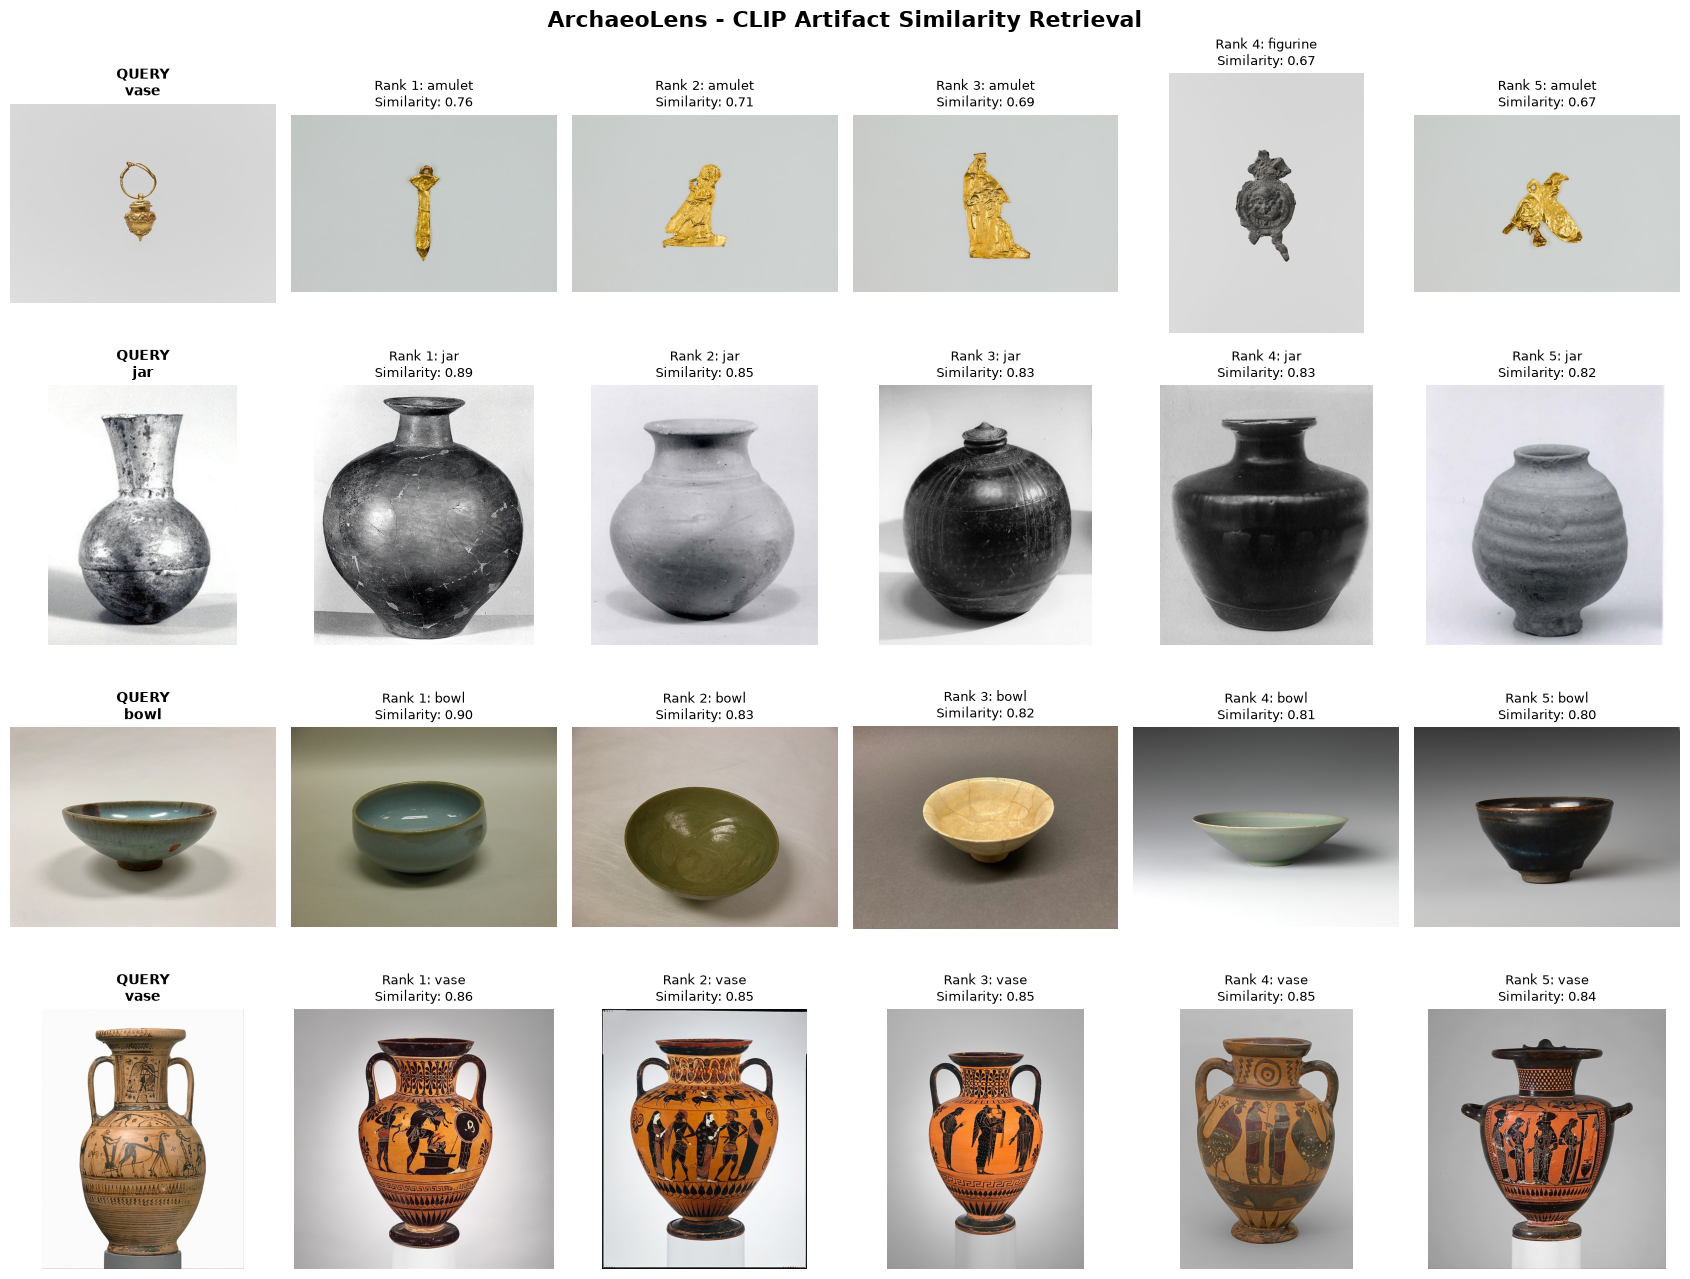


=== RETRIEVAL ENGINE ===
Embedding index: C:\Users\Amir\Desktop\Github Projects\archaeolens-multimodal-deep-learning\app\gallery_index.pt
Gallery metadata: C:\Users\Amir\Desktop\Github Projects\archaeolens-multimodal-deep-learning\app\gallery_metadata.csv
Visualization: C:\Users\Amir\Desktop\Github Projects\archaeolens-multimodal-deep-learning\reports\figures\clip_retrieval_gallery.png
Test set: NOT USED

EXPERIMENT 04 COMPLETE


In [10]:

import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

# ============================================
# ARCHAEOLENS - EXPERIMENT 04
# CLIP IMAGE SIMILARITY RETRIEVAL
# ============================================

# Normalize existing CLIP embeddings
gallery_features = F.normalize(
    X_clip_train.float(), dim=1
)

query_features = F.normalize(
    X_clip_val.float(), dim=1
)

# Cosine similarity: validation queries vs training gallery
similarity = query_features @ gallery_features.T

TOP_K = 5
scores, indices = similarity.topk(TOP_K, dim=1)

# Same-category retrieval evaluation
retrieved_labels = y_clip_train[indices]
matches = retrieved_labels.eq(y_clip_val.unsqueeze(1))

top1_accuracy = matches[:, 0].float().mean().item()
hit_at_5 = matches.any(dim=1).float().mean().item()
precision_at_5 = matches.float().mean().item()

print("=== CLIP IMAGE RETRIEVAL RESULTS ===")
print("Gallery images:", len(train_df))
print("Validation queries:", len(val_df))
print("Embedding dimension:", gallery_features.shape[1])
print(f"Same-category Top-1: {top1_accuracy:.4f}")
print(f"Same-category Hit@5: {hit_at_5:.4f}")
print(f"Same-category Precision@5: {precision_at_5:.4f}")

# Save the gallery index for deployment
app_dir = ROOT / "app"
app_dir.mkdir(parents=True, exist_ok=True)

index_path = app_dir / "gallery_index.pt"
metadata_path = app_dir / "gallery_metadata.csv"

torch.save({
    "embeddings": gallery_features.half().cpu(),
    "architecture": CLIP_ARCH,
    "pretrained": CLIP_WEIGHTS,
    "classes": CLASSES
}, index_path)

train_df.to_csv(metadata_path, index=False)

# Generate qualitative retrieval examples
rng = np.random.default_rng(SEED)
selected = rng.choice(len(val_df), size=4, replace=False)

fig, axes = plt.subplots(4, 6, figsize=(17, 13))

for r, query_idx in enumerate(selected):
    query_record = val_df.iloc[int(query_idx)]

    with Image.open(ROOT / query_record["image_path"]) as img:
        query_image = ImageOps.exif_transpose(img).convert("RGB")

    axes[r, 0].imshow(query_image)
    axes[r, 0].set_title(
        f"QUERY\n{query_record['label']}",
        fontsize=10,
        fontweight="bold"
    )
    axes[r, 0].axis("off")

    for rank in range(TOP_K):
        gallery_idx = indices[query_idx, rank].item()
        retrieved = train_df.iloc[gallery_idx]

        with Image.open(ROOT / retrieved["image_path"]) as img:
            retrieved_image = ImageOps.exif_transpose(
                img
            ).convert("RGB")

        axes[r, rank + 1].imshow(retrieved_image)
        axes[r, rank + 1].set_title(
            f"Rank {rank + 1}: {retrieved['label']}\n"
            f"Similarity: {scores[query_idx, rank]:.2f}",
            fontsize=9
        )
        axes[r, rank + 1].axis("off")

fig.suptitle(
    "ArchaeoLens - CLIP Artifact Similarity Retrieval",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

output = ROOT / "reports/figures/clip_retrieval_gallery.png"

plt.savefig(output, dpi=180, bbox_inches="tight")
plt.show()

print("\n=== RETRIEVAL ENGINE ===")
print("Embedding index:", index_path)
print("Gallery metadata:", metadata_path)
print("Visualization:", output)
print("Test set: NOT USED")
print("\nEXPERIMENT 04 COMPLETE")


In [11]:

# ============================================
# ARCHAEOLENS - EXPERIMENT 04 VERIFICATION
# ============================================

print("=== RETRIEVAL PERFORMANCE ===")
print(f"Top-1 category accuracy: {top1_accuracy:.4f}")
print(f"Hit@5:                  {hit_at_5:.4f}")
print(f"Precision@5:           {precision_at_5:.4f}")

print("\n=== QUERY METADATA INSPECTION ===")

for number, query_idx in enumerate(selected, start=1):
    query_idx = int(query_idx)
    query = val_df.iloc[query_idx]

    print(f"\nQUERY {number}")
    print("Object ID:", query["object_id"])
    print("Dataset label:", query["label"])
    print("Museum object name:", query["object_name"])
    print("Museum title:", query["title"])
    print("Culture:", query["culture"])
    print("Period:", query["period"])
    print("Museum URL:", query["object_url"])

    print("\nTop retrieved artifact:")
    match_idx = indices[query_idx, 0].item()
    match = train_df.iloc[match_idx]

    print("Object ID:", match["object_id"])
    print("Label:", match["label"])
    print("Title:", match["title"])
    print("Similarity:", round(scores[query_idx, 0].item(), 4))

print("\nRETRIEVAL VERIFICATION COMPLETE")


=== RETRIEVAL PERFORMANCE ===
Top-1 category accuracy: 0.8200
Hit@5:                  0.9667
Precision@5:           0.7640

=== QUERY METADATA INSPECTION ===

QUERY 1
Object ID: 243038
Dataset label: vase
Museum object name: Pendant, vase-shaped
Museum title: Gold vase-shaped pendant
Culture: Cypriot or Greek
Period: Classical
Museum URL: https://www.metmuseum.org/art/collection/search/243038

Top retrieved artifact:
Object ID: 561550
Label: amulet
Title: Papyrus scepter (wadj) amulet
Similarity: 0.7597

QUERY 2
Object ID: 308738
Dataset label: jar
Museum object name: Jar
Museum title: Miniature Silver Jar
Culture: Chancay
Period: nan
Museum URL: https://www.metmuseum.org/art/collection/search/308738

Top retrieved artifact:
Object ID: 325596
Label: jar
Title: Ovoid jar
Similarity: 0.8858

QUERY 3
Object ID: 48444
Dataset label: bowl
Museum object name: Bowl
Museum title: Bowl
Culture: China
Period: Yuan dynasty (1271–1368)
Museum URL: https://www.metmuseum.org/art/collection/search/48

Final held-out test: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████| 19/19 [00:24<00:00,  1.27s/it]



=== FINAL CLIP TEST RESULTS ===
Test accuracy: 0.8400
Test Macro F1: 0.8402
Correct: 126
Incorrect: 24

=== TEST CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

        vase     0.8387    0.8667    0.8525        30
        bowl     0.9655    0.9333    0.9492        30
         jar     0.8571    0.8000    0.8276        30
    figurine     0.8148    0.7333    0.7719        30
      amulet     0.7429    0.8667    0.8000        30

    accuracy                         0.8400       150
   macro avg     0.8438    0.8400    0.8402       150
weighted avg     0.8438    0.8400    0.8402       150


=== FINAL RETRIEVAL TEST ===
Top-1:       0.8200
Hit@5:       0.9667
Precision@5: 0.7587


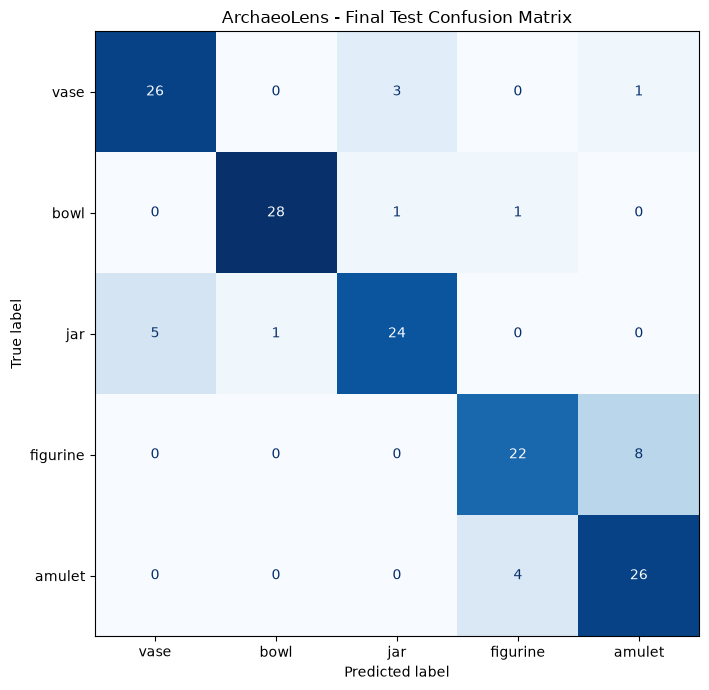


FINAL TEST EVALUATION COMPLETE
Metrics saved: C:\Users\Amir\Desktop\Github Projects\archaeolens-multimodal-deep-learning\reports\final_test_metrics.json
Test set evaluated without retraining.


In [12]:

import json
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from tqdm.auto import tqdm

# ============================================
# ARCHAEOLENS - FINAL HELD-OUT EVALUATION
# ============================================

# Load the selected model, without retraining
checkpoint = torch.load(
    ROOT / "models/clip_linear_probe_best.pt",
    map_location="cpu",
    weights_only=True
)

assert checkpoint["classes"] == CLASSES
assert checkpoint["architecture"] == CLIP_ARCH

clip_head.load_state_dict(checkpoint["head_state_dict"])
clip_head.eval()
clip_model.eval()

# Previously unseen test images
clip_test_dataset = ArtifactDataset(
    test_df,
    clip_preprocess
)

clip_test_loader = DataLoader(
    clip_test_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

test_features = []
test_labels = []
test_predictions = []

with torch.inference_mode():
    for batch_images, batch_labels in tqdm(
        clip_test_loader,
        desc="Final held-out test"
    ):
        embeddings = clip_model.encode_image(
            batch_images.to(DEVICE)
        ).float()

        embeddings = F.normalize(
            embeddings, dim=-1
        )

        logits = clip_head(
            embeddings * checkpoint["feature_scale"]
        )

        predictions = logits.argmax(dim=1)

        test_features.append(embeddings.cpu())
        test_labels.extend(batch_labels.tolist())
        test_predictions.extend(
            predictions.cpu().tolist()
        )

test_features = torch.cat(test_features)
y_true = np.array(test_labels)
y_pred = np.array(test_predictions)

assert len(y_true) == 150

# Classification metrics
test_accuracy = accuracy_score(y_true, y_pred)
test_macro_f1 = f1_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

report = classification_report(
    y_true, y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=CLASSES,
    digits=4,
    zero_division=0
)

print("\n=== FINAL CLIP TEST RESULTS ===")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test Macro F1: {test_macro_f1:.4f}")
print("Correct:", int((y_true == y_pred).sum()))
print("Incorrect:", int((y_true != y_pred).sum()))

print("\n=== TEST CLASSIFICATION REPORT ===")
print(report)

# Evaluate retrieval against training gallery only
gallery = torch.load(
    ROOT / "app/gallery_index.pt",
    map_location="cpu",
    weights_only=True
)

gallery_features = F.normalize(
    gallery["embeddings"].float(),
    dim=-1
)

gallery_metadata = pd.read_csv(
    ROOT / "app/gallery_metadata.csv"
)

assert len(gallery_metadata) == len(gallery_features)

label_map = {
    name: i for i, name in enumerate(CLASSES)
}

gallery_labels = torch.tensor([
    label_map[label]
    for label in gallery_metadata["label"]
])

similarities = test_features @ gallery_features.T

top_indices = similarities.topk(5, dim=1).indices
retrieved_labels = gallery_labels[top_indices]

matches = retrieved_labels.eq(
    torch.tensor(y_true).unsqueeze(1)
)

retrieval_top1 = matches[:, 0].float().mean().item()
retrieval_hit5 = matches.any(dim=1).float().mean().item()
retrieval_precision5 = matches.float().mean().item()

print("\n=== FINAL RETRIEVAL TEST ===")
print(f"Top-1:       {retrieval_top1:.4f}")
print(f"Hit@5:       {retrieval_hit5:.4f}")
print(f"Precision@5: {retrieval_precision5:.4f}")

# Save reproducible results
metrics = {
    "model": "CLIP ViT-B/32 Linear Probe",
    "test_samples": 150,
    "gallery_samples": len(gallery_metadata),
    "accuracy": test_accuracy,
    "macro_f1": test_macro_f1,
    "retrieval_top1": retrieval_top1,
    "retrieval_hit_at_5": retrieval_hit5,
    "retrieval_precision_at_5": retrieval_precision5
}

report_dir = ROOT / "reports"
figure_dir = report_dir / "figures"

report_dir.mkdir(exist_ok=True)
figure_dir.mkdir(exist_ok=True)

(report_dir / "final_test_metrics.json").write_text(
    json.dumps(metrics, indent=4),
    encoding="utf-8"
)

(report_dir / "final_test_report.txt").write_text(
    report,
    encoding="utf-8"
)

predictions_df = test_df.copy()
predictions_df["predicted_label"] = [
    CLASSES[i] for i in y_pred
]
predictions_df["correct"] = y_true == y_pred

predictions_df.to_csv(
    report_dir / "final_test_predictions.csv",
    index=False
)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES))
)

fig, ax = plt.subplots(figsize=(8, 7))

ConfusionMatrixDisplay(
    cm,
    display_labels=CLASSES
).plot(
    ax=ax,
    cmap="Blues",
    colorbar=False,
    values_format="d"
)

ax.set_title("ArchaeoLens - Final Test Confusion Matrix")
plt.tight_layout()

plt.savefig(
    figure_dir / "final_test_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nFINAL TEST EVALUATION COMPLETE")
print("Metrics saved:", report_dir / "final_test_metrics.json")
print("Test set evaluated without retraining.")


Images analyzed: 1000

=== NEAR-DUPLICATE AUDIT ===
Total images: 1000
Cross-split candidate pairs: 11
Identical URL pairs: 1

Closest candidate pairs:
558521 (train) vs 558514 (val) | pHash=0 | dHash=0
570361 (train) vs 555603 (test) | pHash=4 | dHash=16
309470 (train) vs 309469 (test) | pHash=6 | dHash=10
478865 (train) vs 478830 (test) | pHash=6 | dHash=14
42439 (train) vs 75938 (test) | pHash=6 | dHash=16
473845 (train) vs 463900 (val) | pHash=8 | dHash=4
310212 (val) vs 308593 (test) | pHash=8 | dHash=10
550918 (train) vs 550921 (test) | pHash=10 | dHash=7
254846 (train) vs 247282 (test) | pHash=10 | dHash=7
247254 (train) vs 247282 (test) | pHash=10 | dHash=9


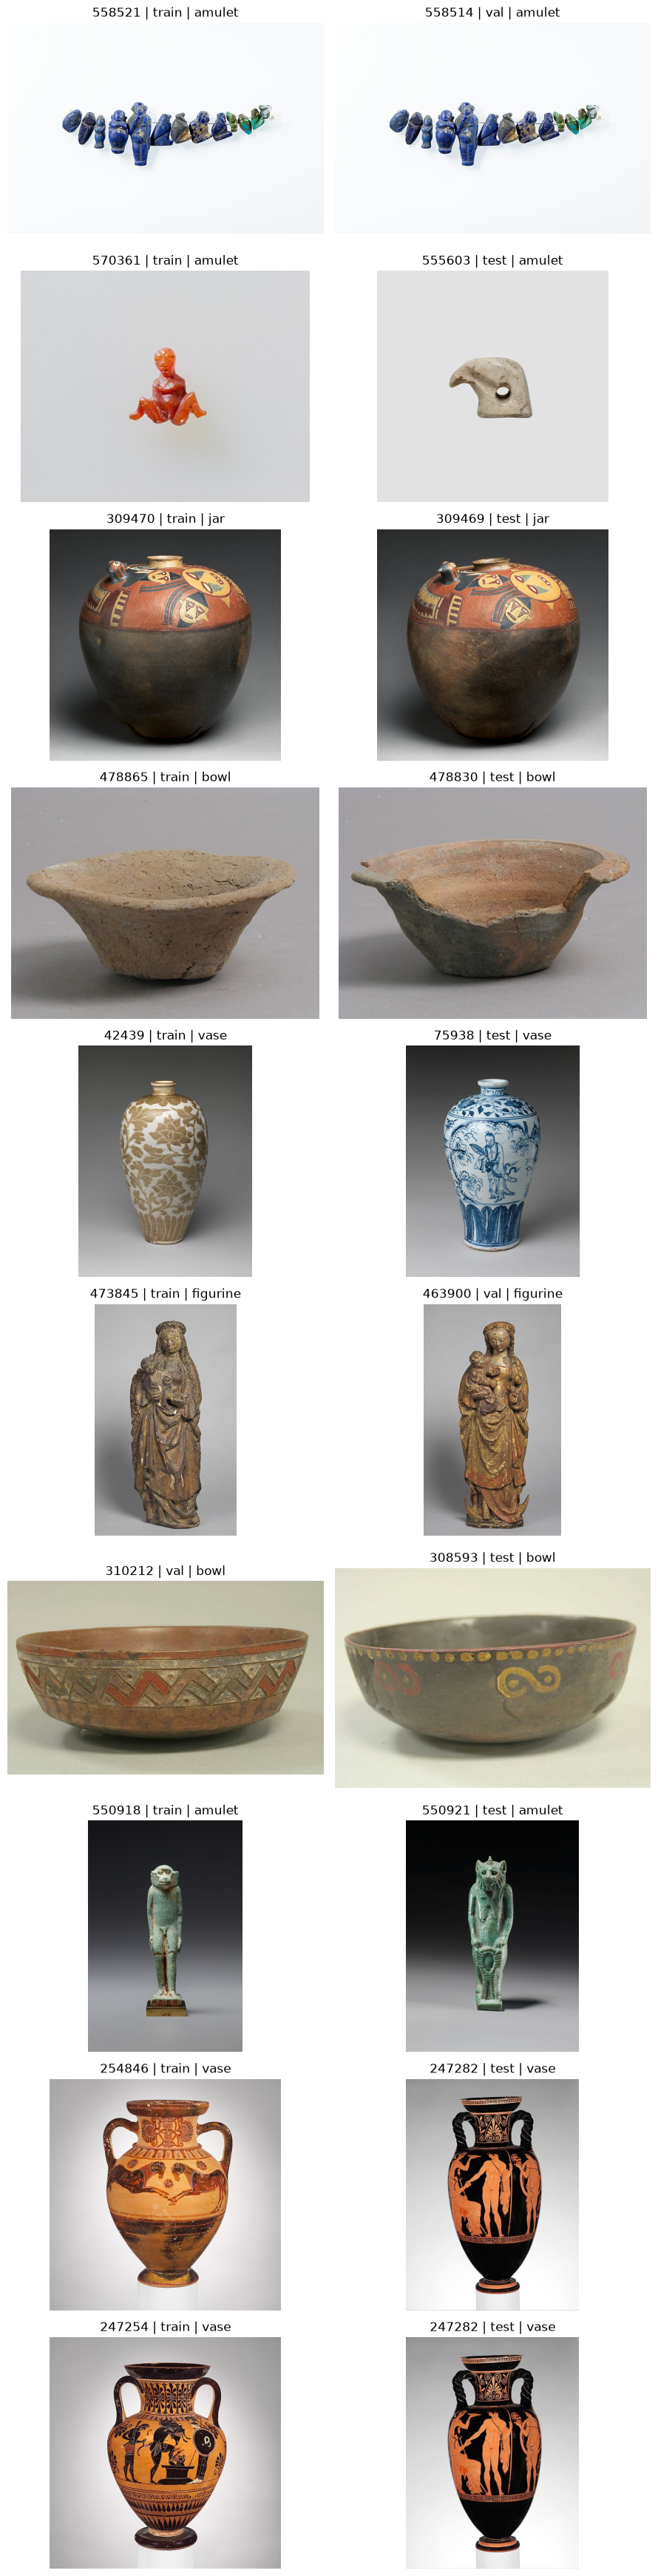

Review gallery: C:\Users\Amir\Desktop\Github Projects\archaeolens-multimodal-deep-learning\reports\figures\near_duplicate_review.png
Candidate report: C:\Users\Amir\Desktop\Github Projects\archaeolens-multimodal-deep-learning\reports\near_duplicate_candidates.csv

AUDIT COMPLETE


In [13]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image, ImageOps
from scipy.fft import dctn

# ==========================================
# ARCHAEOLENS - NEAR-DUPLICATE LEAKAGE AUDIT
# ==========================================

def image_hashes(path):
    with Image.open(path) as image:
        gray = ImageOps.exif_transpose(image).convert("L")

        # 63-bit perceptual hash
        small = gray.resize((32, 32), Image.Resampling.LANCZOS)
        pixels = np.asarray(small, dtype=np.float32)
        frequencies = dctn(pixels, norm="ortho")[:8, :8]
        values = frequencies.flatten()[1:]

        phash = int(
            "".join("1" if x else "0"
                    for x in values > np.median(values)),
            2
        )

        # 64-bit difference hash
        small = gray.resize((9, 8), Image.Resampling.LANCZOS)
        pixels = np.asarray(small, dtype=np.int16)
        differences = pixels[:, 1:] > pixels[:, :-1]

        dhash = int(
            "".join("1" if x else "0"
                    for x in differences.flatten()),
            2
        )

    return phash, dhash


datasets = {
    "train": train_df,
    "val": val_df,
    "test": test_df
}

records = []

for split, dataframe in datasets.items():
    for _, row in dataframe.iterrows():
        path = ROOT / row["image_path"]
        phash, dhash = image_hashes(path)

        records.append({
            "split": split,
            "object_id": str(row["object_id"]),
            "label": row["label"],
            "image_path": str(path),
            "image_url": str(row.get("image_url", "")),
            "phash": phash,
            "dhash": dhash
        })

print("Images analyzed:", len(records))

candidates = []

for i, first in enumerate(records):
    for second in records[i + 1:]:

        if first["split"] == second["split"]:
            continue

        p_distance = (
            first["phash"] ^ second["phash"]
        ).bit_count()

        d_distance = (
            first["dhash"] ^ second["dhash"]
        ).bit_count()

        same_url = (
            first["image_url"] == second["image_url"]
            and bool(first["image_url"])
        )

        # Potential near-duplicates for manual review
        suspicious = (
            same_url
            or p_distance <= 6
            or (p_distance <= 10 and d_distance <= 10)
        )

        if suspicious:
            candidates.append({
                "split_a": first["split"],
                "split_b": second["split"],
                "id_a": first["object_id"],
                "id_b": second["object_id"],
                "label_a": first["label"],
                "label_b": second["label"],
                "phash_distance": p_distance,
                "dhash_distance": d_distance,
                "same_image_url": same_url,
                "path_a": first["image_path"],
                "path_b": second["image_path"]
            })

candidates.sort(
    key=lambda x: (
        not x["same_image_url"],
        x["phash_distance"],
        x["dhash_distance"]
    )
)

output = ROOT / "reports/near_duplicate_candidates.csv"
pd.DataFrame(candidates, columns=[
    "split_a", "split_b", "id_a", "id_b",
    "label_a", "label_b", "phash_distance",
    "dhash_distance", "same_image_url",
    "path_a", "path_b"
]).to_csv(output, index=False)

print("\n=== NEAR-DUPLICATE AUDIT ===")
print("Total images:", len(records))
print("Cross-split candidate pairs:", len(candidates))
print("Identical URL pairs:",
      sum(c["same_image_url"] for c in candidates))

print("\nClosest candidate pairs:")
for item in candidates[:10]:
    print(
        f"{item['id_a']} ({item['split_a']}) vs "
        f"{item['id_b']} ({item['split_b']}) | "
        f"pHash={item['phash_distance']} | "
        f"dHash={item['dhash_distance']}"
    )

if candidates:
    samples = candidates[:10]

    fig, axes = plt.subplots(
        len(samples), 2,
        figsize=(9, 3.5 * len(samples)),
        squeeze=False
    )

    for row_index, pair in enumerate(samples):
        for col_index, suffix in enumerate(["a", "b"]):
            ax = axes[row_index, col_index]

            with Image.open(pair[f"path_{suffix}"]) as img:
                ax.imshow(img.convert("RGB"))

            ax.set_title(
                f"{pair[f'id_{suffix}']} | "
                f"{pair[f'split_{suffix}']} | "
                f"{pair[f'label_{suffix}']}"
            )
            ax.axis("off")

    plt.tight_layout()

    gallery_path = (
        ROOT / "reports/figures/near_duplicate_review.png"
    )

    plt.savefig(gallery_path, dpi=150, bbox_inches="tight")
    plt.show()

    print("Review gallery:", gallery_path)
else:
    print("No candidate pairs met the hash thresholds.")

print("Candidate report:", output)
print("\nAUDIT COMPLETE")


In [14]:

import json
import torch
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

# ==========================================
# ARCHAEOLENS - LEAKAGE SENSITIVITY ANALYSIS
# ==========================================

def image_urls(df):
    return df["image_url"].fillna("").astype(str).str.strip()

train_urls = set(image_urls(train_df)) - {""}
val_urls = set(image_urls(val_df)) - {""}

# Check for identical image URLs across splits
val_overlap = image_urls(val_df).isin(train_urls)
test_overlap = image_urls(test_df).isin(train_urls | val_urls)

print("=== CROSS-SPLIT IMAGE AUDIT ===")
print("Train-validation overlaps:", int(val_overlap.sum()))
print("Test overlaps:", int(test_overlap.sum()))

print("\nAffected validation object IDs:")
print(val_df.loc[val_overlap, "object_id"].tolist())

print("\nAffected test object IDs:")
print(test_df.loc[test_overlap, "object_id"].tolist())

# Restore the selected, already-trained CLIP classifier
checkpoint = torch.load(
    ROOT / "models/clip_linear_probe_best.pt",
    map_location="cpu",
    weights_only=True
)

clip_head.load_state_dict(checkpoint["head_state_dict"])
clip_head.eval()

with torch.inference_mode():
    logits = clip_head(
        X_clip_val.to(DEVICE)
    )
    predictions = logits.argmax(1).cpu().numpy()

actual = y_clip_val.numpy()
keep = (~val_overlap).to_numpy()

original_accuracy = accuracy_score(actual, predictions)
original_f1 = f1_score(
    actual, predictions,
    average="macro",
    zero_division=0
)

clean_accuracy = accuracy_score(
    actual[keep], predictions[keep]
)
clean_f1 = f1_score(
    actual[keep], predictions[keep],
    average="macro",
    zero_division=0
)

print("\n=== VALIDATION SENSITIVITY RESULTS ===")
print("Original validation images:", len(actual))
print("Retained after URL audit:", int(keep.sum()))
print(f"Original accuracy: {original_accuracy:.4f}")
print(f"Original Macro F1: {original_f1:.4f}")
print(f"Filtered accuracy: {clean_accuracy:.4f}")
print(f"Filtered Macro F1: {clean_f1:.4f}")

audit = {
    "original_validation_count": len(actual),
    "filtered_validation_count": int(keep.sum()),
    "train_validation_url_overlaps": int(val_overlap.sum()),
    "test_url_overlaps": int(test_overlap.sum()),
    "original_validation_accuracy": original_accuracy,
    "original_validation_macro_f1": original_f1,
    "filtered_validation_accuracy": clean_accuracy,
    "filtered_validation_macro_f1": clean_f1,
    "note": (
        "Sensitivity analysis only. The original "
        "checkpoint was selected using the full "
        "validation dataset."
    )
}

output = ROOT / "reports/leakage_sensitivity.json"

output.write_text(
    json.dumps(audit, indent=4),
    encoding="utf-8"
)

print("\nReport saved:", output)
print("MODEL AND DATA SPLITS UNCHANGED")


=== CROSS-SPLIT IMAGE AUDIT ===
Train-validation overlaps: 1
Test overlaps: 0

Affected validation object IDs:
[558514]

Affected test object IDs:
[]

=== VALIDATION SENSITIVITY RESULTS ===
Original validation images: 150
Retained after URL audit: 149
Original accuracy: 0.8733
Original Macro F1: 0.8723
Filtered accuracy: 0.8725
Filtered Macro F1: 0.8718

Report saved: C:\Users\Amir\Desktop\Github Projects\archaeolens-multimodal-deep-learning\reports\leakage_sensitivity.json
MODEL AND DATA SPLITS UNCHANGED
